In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
import scipy as scipy
import seaborn as sns

import ssl 
ssl._create_default_https_context = ssl._create_unverified_context

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# Exercise

We shall once again play around with the Boston housing data set

In [2]:
from sklearn.datasets import fetch_california_housing
data = fetch_california_housing(as_frame=True)

And again we treat it as a classification problem:

In [3]:
c = np.array([1 if y > np.median(data['target']) else 0 for y in data['target']])
X_train, X_test, c_train, c_test = train_test_split(data['data'], c, random_state=0)

### *Exercise:* Below are some pairwise scatter plots of some of the features conditional on the class state 0
* Try visualizing other (pairs of features) features to get a better understanding of the (conditional) data. Feel free to also consider class 1.

In [4]:
# Pick the data belonging to class 0
X_0 = data['data'][c==0]

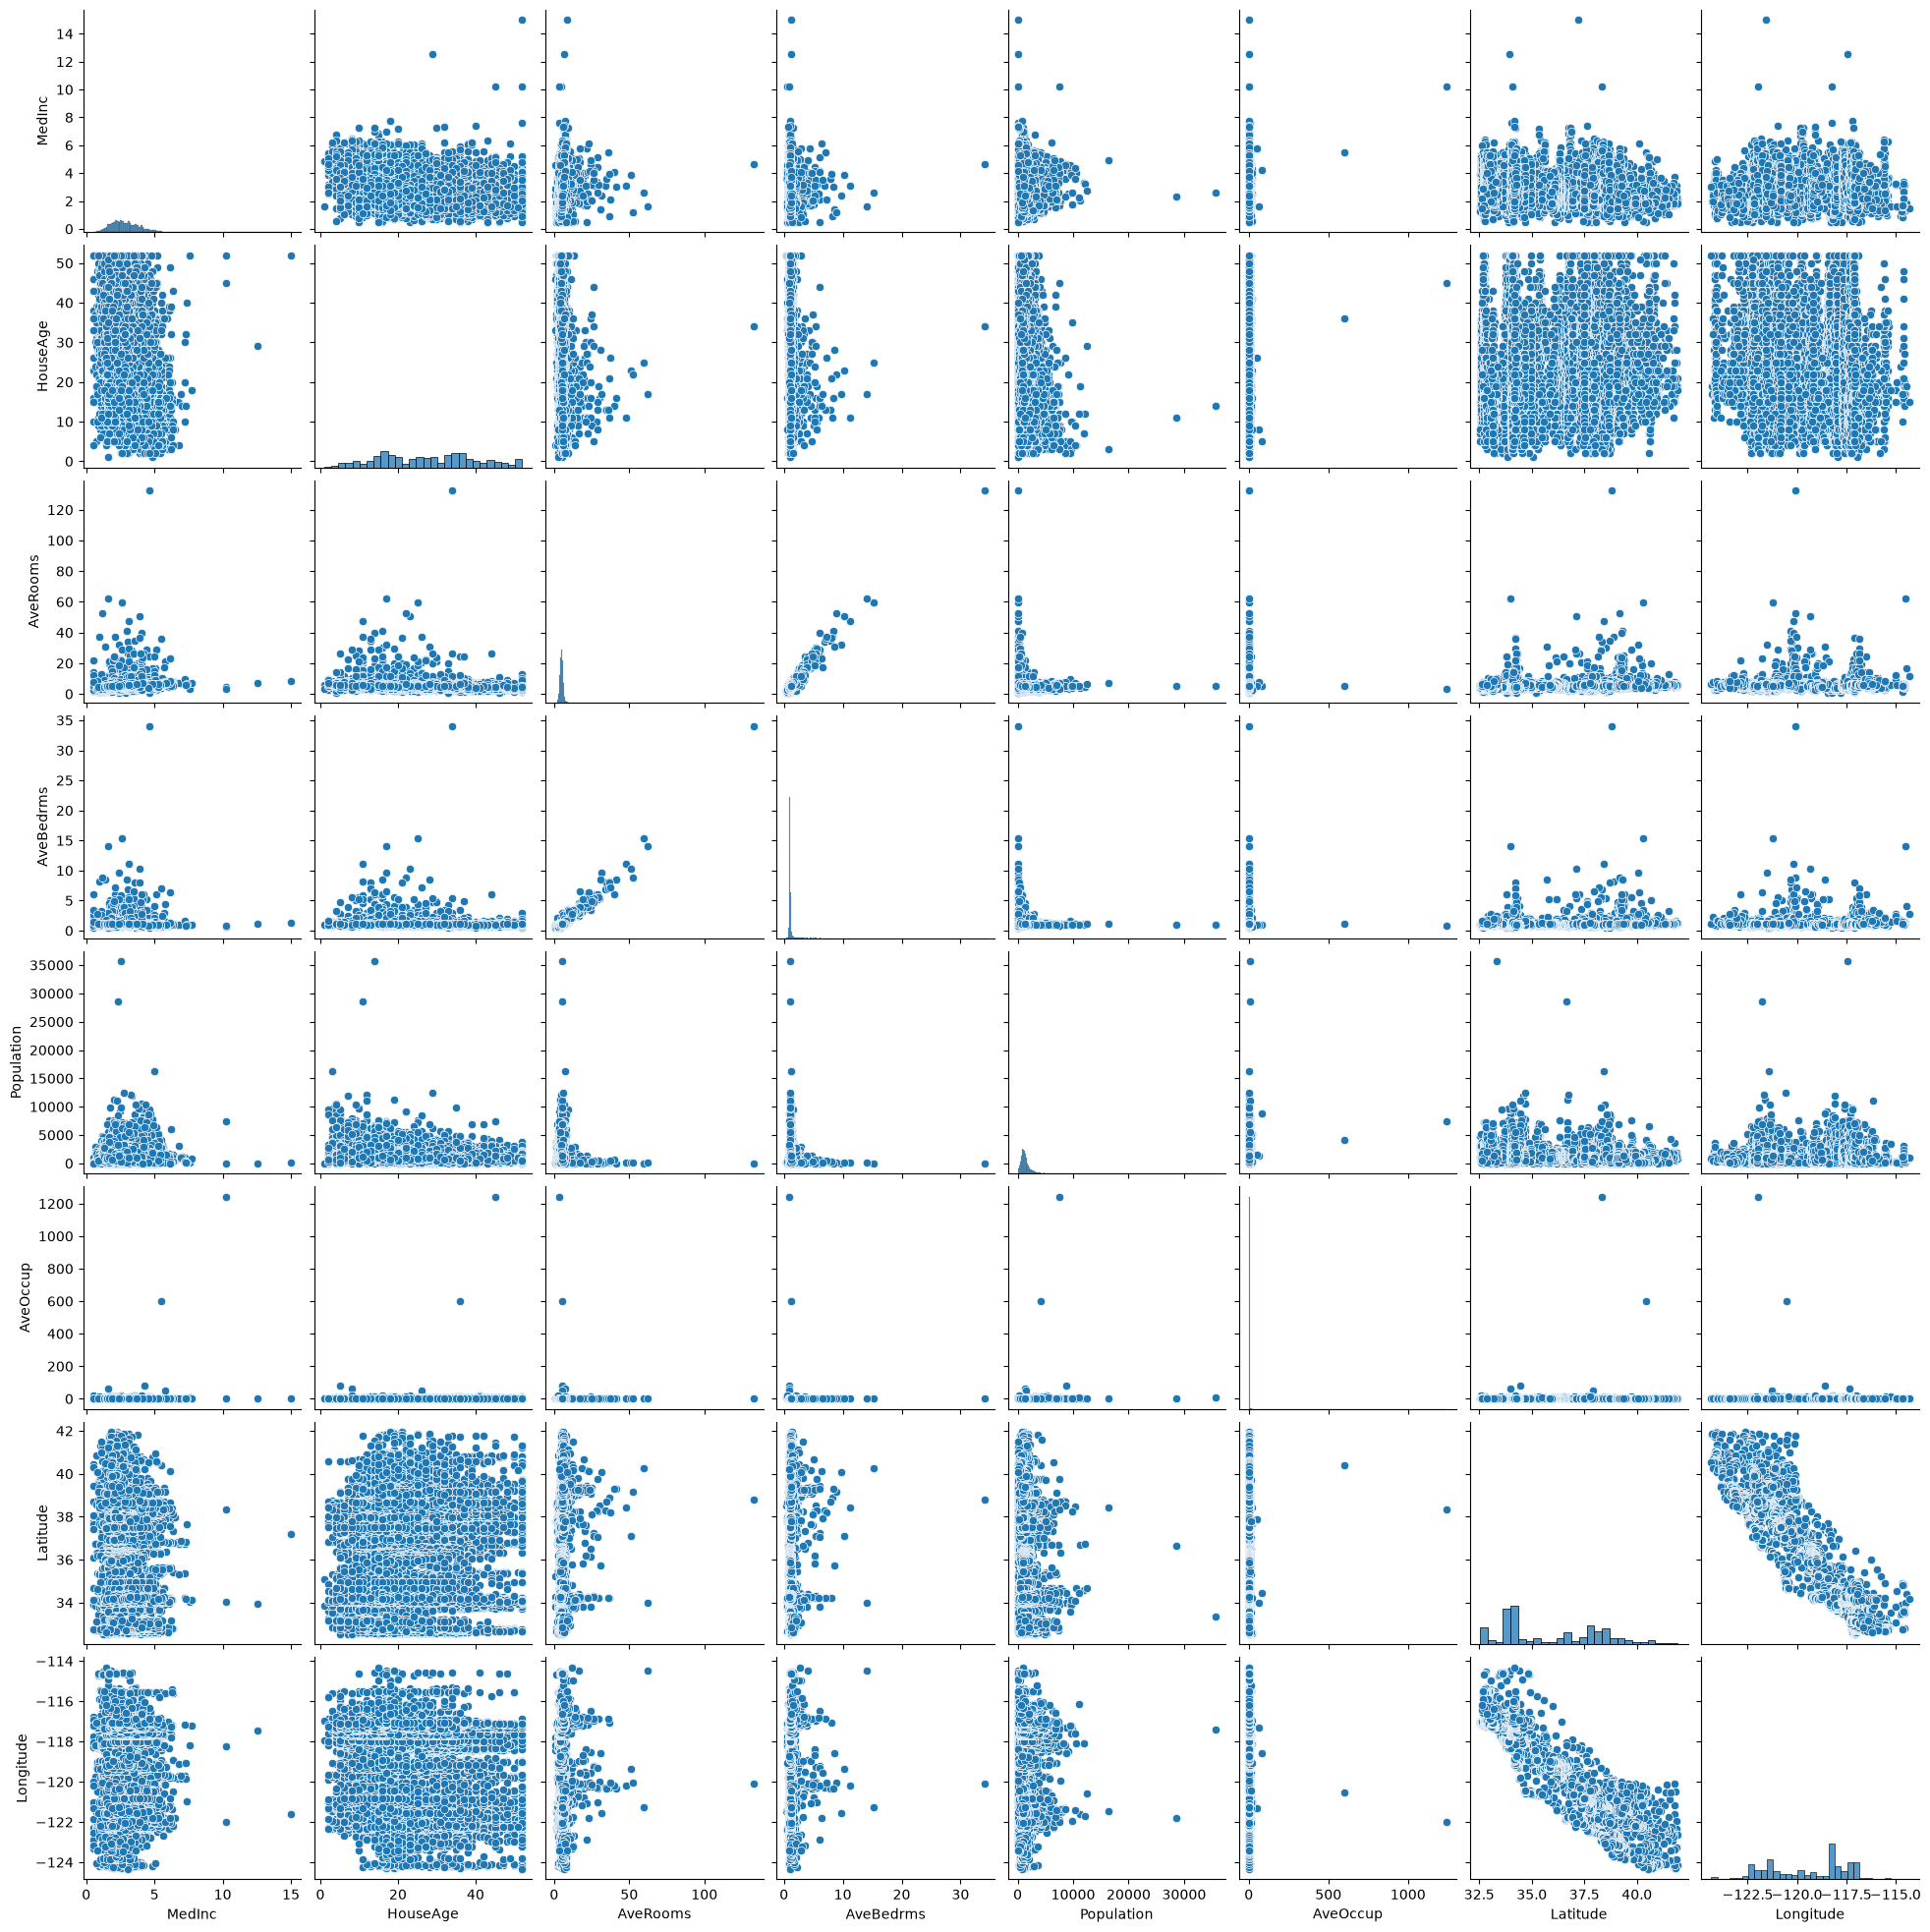

In [5]:
sns.pairplot(pd.DataFrame(X_0,columns=data['feature_names']))

Learn a Gaussian NB model:

In [6]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_train, c_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[7685.,7795.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.5,0.5]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.00131
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 8)","[[ 2.87, 27.78, 5.2 ,..., 3.24, 35.93,-119.48], [ 4.87, 29.47, 5.66,..., 2.84, 35.33,-119.66]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 8)","[[ 1.07,151.93, 7.04,..., 48.92, 5.42, 4.09], [ 4.1 ,164.05, 5.7 ,..., 39.49, 3.56, 3.94]]"


### *Exercise:* Model evaluation
* What is the performance of the model on the training set and test set, respectively?

### *Exercise:* Revisit the model to improve performance
* Can you improve the performance (as measured on the test set) by removing features? If so, which ones and how do you select them?
* Note: to remove the column with index 4 from a numpy array X you can use (the '1' in the expression indicates that we wish to delete a column.) 
    - `X_reduced = np.delete(X,4,1)`